# Post 2: Prefill vs Decode

Reproduces every number in [Post 2](README.md): how long the **prompt phase (prefill)** and one **decode** token take
for Qwen3.8-27B at batch 1, and why one is compute-bound and the other memory-bound.

* **No GPU (Mac / Windows / Linux laptop):** the notebook reads the stored results in `results/post2/` and prints the post's numbers.
* **NVIDIA GPU + vLLM:** it runs `vllm bench latency` on your GPU and prints *your* numbers next to the stored H100 ones.
* **Google Colab:** the first code cell fetches the repo, then it runs like a laptop (stored results).

Run all cells top to bottom. Setup instructions: [`posts/README.md`](../README.md).

In [1]:
# Google Colab only: fetch the repo at this post's tag so results/post2/ is there; does nothing on a laptop or in VS Code.
# Colab already has pandas, numpy and matplotlib, so stored mode needs no pip install.
import os, sys, subprocess
if "google.colab" in sys.modules:
    REPO, TAG = "/content/Sillybench", "post-02"
    if not os.path.isdir(REPO):
        subprocess.run(["git", "-c", "advice.detachedHead=false", "clone", "-q", "--depth", "1", "--branch", TAG,
                        "https://github.com/tgarg01/Sillybench.git", REPO], check=True)
    os.chdir(f"{REPO}/posts/post-02")

In [2]:
import json, shutil, subprocess, datetime
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# repo root = the folder that contains results/
ROOT = Path.cwd().resolve()
while not (ROOT / "results").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
STORED = ROOT / "results" / "post2" / "h100-sxm_2026-10-09"

MODEL = "Qwen/Qwen3.8-27B"
INPUT_LEN, OUTPUT_LEN, BATCH = 512, 128, 1     # 512-token prompt; 128 output tokens to time decode
WARMUP, ITERS = 3, 5
# the vLLM engine settings used for the stored H100 run
VLLM_ARGS = ["--language-model-only", "--max-model-len", "8192", "--max-num-seqs", "256",
             "--gpu-memory-utilization", "0.92", "--no-enable-prefix-caching"]

MODE = "auto"   # "auto": measure if this machine has an NVIDIA GPU and vLLM, else use stored results; or "gpu" / "stored"
print("repo:", ROOT)

repo: Sillybench


## 1. GPU or stored results?

In [3]:
def gpu_name():
    if shutil.which("nvidia-smi") is None:
        return None
    r = subprocess.run(["nvidia-smi", "--query-gpu=name", "--format=csv,noheader"], capture_output=True, text=True)
    return r.stdout.strip().splitlines()[0] if r.returncode == 0 and r.stdout.strip() else None

GPU = gpu_name()
if MODE == "auto":
    MODE = "gpu" if (GPU and shutil.which("vllm")) else "stored"
print("mode:", MODE, "| GPU:", GPU or "none found")
if MODE == "stored":
    print("Using the stored H100 SXM results in", STORED.relative_to(ROOT))

mode: stored | GPU: none found
Using the stored H100 SXM results in results/post2/h100-sxm_2026-10-09


## 2. Measure (GPU) or load (stored)

Two `vllm bench latency` runs, each averaged over 5 iterations:
* `--output-len 1`: the prompt phase alone (512 tokens in, first token out) = **prefill time**
* `--output-len 128`: prefill + 127 decode steps, so **decode time per token** = (t128 - t1) / 127

On an H100 this takes ~10 minutes the first time (model download ~55 GB + engine start-up), then ~2 minutes.

In [4]:
def bench(out_len, path):
    cmd = ["vllm", "bench", "latency", "--model", MODEL, *VLLM_ARGS,
           "--batch-size", str(BATCH), "--input-len", str(INPUT_LEN), "--output-len", str(out_len),
           "--num-iters-warmup", str(WARMUP), "--num-iters", str(ITERS), "--output-json", str(path)]
    print("$", " ".join(cmd))
    subprocess.run(cmd, check=True)

if MODE == "gpu":
    slug = GPU.lower().replace("nvidia", "").strip().replace(" ", "-")
    RES = ROOT / "results" / "post2" / f"{slug}_{datetime.date.today()}"
    RES.mkdir(parents=True, exist_ok=True)
    for o in (1, OUTPUT_LEN):
        f = RES / f"lat_b{BATCH}_in{INPUT_LEN}_out{o}.json"
        if not f.exists():          # re-running the notebook re-uses finished measurements
            bench(o, f)
else:
    RES = STORED

lat = {o: json.loads((RES / f"lat_b{BATCH}_in{INPUT_LEN}_out{o}.json").read_text())["avg_latency"]
       for o in (1, OUTPUT_LEN)}
prefill_ms = lat[1] * 1e3
decode_ms = (lat[OUTPUT_LEN] - lat[1]) / (OUTPUT_LEN - 1) * 1e3
print(f"results from: {RES.relative_to(ROOT)}")
print(f"prefill ({INPUT_LEN} tokens): {prefill_ms:.2f} ms   |   decode: {decode_ms:.2f} ms per token")

results from: results/post2/h100-sxm_2026-10-09
prefill (512 tokens): 54.33 ms   |   decode: 20.55 ms per token


## 3. How many bytes and FLOPs? (from the model's `config.json`)

Every token has to pass through every weight matrix (GEMM). So:
* **bytes read per forward pass** = all GEMM weights x 2 bytes (BF16), read once per pass
* **FLOPs** = 2 x weights per token (one multiply + one add per weight)

In prefill vLLM computes the output head (LM head) only for the last prompt token.

In [5]:
cfg_path = RES / "model_config.json"
if not cfg_path.exists():
    try:
        from huggingface_hub import hf_hub_download
        shutil.copy(hf_hub_download(MODEL, "config.json"), cfg_path)
    except Exception as e:
        print("could not download config.json, using the stored copy:", e)
        cfg_path = STORED / "model_config.json"
cfg = json.loads(cfg_path.read_text())
c = cfg.get("text_config", cfg)

H, I, V = c["hidden_size"], c["intermediate_size"], c["vocab_size"]
types = c["layer_types"]
L, L_lin, L_full = len(types), types.count("linear_attention"), types.count("full_attention")
n_h, hd, n_kv = c["num_attention_heads"], c["head_dim"], c["num_key_value_heads"]
gate = 2 if c.get("attn_output_gate") else 1
lk_h, lk_d, lv_h, lv_d = (c["linear_num_key_heads"], c["linear_key_head_dim"],
                          c["linear_num_value_heads"], c["linear_value_head_dim"])

# (name, matrices per forward pass, out, in) for every GEMM in the model
gemms = pd.DataFrame([
    ("mlp.gate_up",            L,      2 * I,                          H),
    ("mlp.down",               L,      H,                              I),
    ("linear_attn.in_proj",    L_lin,  2 * lk_h * lk_d + 2 * lv_h * lv_d, H),
    ("linear_attn.in_proj_ba", L_lin,  2 * lv_h,                       H),
    ("linear_attn.out_proj",   L_lin,  H,                              lv_h * lv_d),
    ("attn.qkv",               L_full, n_h * hd * gate + 2 * n_kv * hd, H),
    ("attn.o_proj",            L_full, H,                              n_h * hd),
    ("lm_head",                1,      V,                              H),
], columns=["gemm", "per_pass", "N", "K"])
gemms["params_M"] = gemms.per_pass * gemms.N * gemms.K / 1e6

P = gemms.params_M.sum() * 1e6
P_head = V * H
WEIGHT_BYTES = 2 * P                                        # BF16
FLOP_DECODE = 2 * P                                         # one token, LM head included
FLOP_PREFILL = INPUT_LEN * 2 * (P - P_head) + 2 * P_head    # all prompt tokens, LM head once
print(f"GEMM parameters: {P/1e9:.2f} B  ->  weights read per pass: {WEIGHT_BYTES/1e9:.2f} GB")
print(f"FLOPs: decode {FLOP_DECODE/1e9:.1f} GFLOP per token, prefill {FLOP_PREFILL/1e12:.1f} TFLOP for {INPUT_LEN} tokens")
gemms.round(1)

GEMM parameters: 25.62 B  ->  weights read per pass: 51.24 GB
FLOPs: decode 51.2 GFLOP per token, prefill 24.9 TFLOP for 512 tokens


,gemm,per_pass,N,K,params_M
0,mlp.gate_up,64,34816,5120,11408.5
1,mlp.down,64,5120,17408,5704.3
2,linear_attn.in_proj,48,16384,5120,4026.5
3,linear_attn.in_proj_ba,48,96,5120,23.6
4,linear_attn.out_proj,48,5120,6144,1509.9
5,attn.qkv,16,14336,5120,1174.4
6,attn.o_proj,16,5120,6144,503.3
7,lm_head,1,248320,5120,1271.4


## 4. The GPU's limits (NVIDIA datasheets: dense BF16 Tensor Core TFLOP/s, memory TB/s)

In [6]:
PEAKS = {
    "H100 80GB HBM3": (989, 3.35),   # H100 SXM
    "H100 NVL":       (835, 3.9),
    "H100 PCIe":      (756, 2.0),
    "A100-SXM4-80GB": (312, 2.039),
    "A100-SXM4-40GB": (312, 1.555),
    "A100 80GB PCIe": (312, 1.935),
    "L40S":           (362, 0.864),
}
name = GPU if MODE == "gpu" else "H100 80GB HBM3"
match = next((k for k in PEAKS if k.lower() in name.lower()), None)
if match is None:
    raise SystemExit(f"Unknown GPU {name!r}: add its dense BF16 TFLOP/s and memory TB/s to PEAKS above.")
PEAK_TF, PEAK_TB = PEAKS[match]
RIDGE = PEAK_TF / PEAK_TB
print(f"{match}: {PEAK_TF} TFLOP/s, {PEAK_TB} TB/s  ->  balance point {RIDGE:.0f} FLOPs per byte")

H100 80GB HBM3: 989 TFLOP/s, 3.35 TB/s  ->  balance point 295 FLOPs per byte


## 5. The post's numbers

In [7]:
pre_s, dec_s = prefill_ms / 1e3, decode_ms / 1e3
rows = {
    "time":                    (f"{prefill_ms:.1f} ms for {INPUT_LEN} tokens", f"{decode_ms:.1f} ms for 1 token"),
    "time per token":          (f"{prefill_ms/INPUT_LEN:.3f} ms", f"{decode_ms:.2f} ms"),
    "compute (TFLOP/s)":       (f"{FLOP_PREFILL/pre_s/1e12:.0f}", f"{FLOP_DECODE/dec_s/1e12:.2f}"),
    "% of peak compute":       (f"{100*FLOP_PREFILL/pre_s/1e12/PEAK_TF:.1f}%", f"{100*FLOP_DECODE/dec_s/1e12/PEAK_TF:.2f}%"),
    "memory (TB/s)":           (f"{WEIGHT_BYTES/pre_s/1e12:.2f}", f"{WEIGHT_BYTES/dec_s/1e12:.2f}"),
    "% of peak memory":        (f"{100*WEIGHT_BYTES/pre_s/1e12/PEAK_TB:.0f}%", f"{100*WEIGHT_BYTES/dec_s/1e12/PEAK_TB:.0f}%"),
    "FLOPs per byte":          (f"{FLOP_PREFILL/WEIGHT_BYTES:.0f}", f"{FLOP_DECODE/WEIGHT_BYTES:.1f}"),
}
table = pd.DataFrame(rows, index=["Prefill", "Decode"]).T
display(table)
ai_pre, ai_dec = FLOP_PREFILL / WEIGHT_BYTES, FLOP_DECODE / WEIGHT_BYTES
print(f"decode takes {decode_ms / (prefill_ms / INPUT_LEN):.0f}x more time per token than prefill")
print(f"prefill: {ai_pre:.0f} FLOPs/byte {'>' if ai_pre > RIDGE else '<'} {RIDGE:.0f} -> "
      f"{'compute' if ai_pre > RIDGE else 'memory'}-bound")
print(f"decode : {ai_dec:.1f} FLOPs/byte {'>' if ai_dec > RIDGE else '<'} {RIDGE:.0f} -> "
      f"{'compute' if ai_dec > RIDGE else 'memory'}-bound")
print(f"decode floor: {WEIGHT_BYTES/1e9:.1f} GB / {PEAK_TB} TB/s = {WEIGHT_BYTES/PEAK_TB/1e9:.1f} ms per token "
      f"(measured {decode_ms:.1f} ms)")

,Prefill,Decode
time,54.3 ms for 512 tokens,20.6 ms for 1 token
time per token,0.106 ms,20.55 ms
compute (TFLOP/s),459,2.49
% of peak compute,46.4%,0.25%
memory (TB/s),0.94,2.49
% of peak memory,28%,74%
FLOPs per byte,487,1.0


decode takes 194x more time per token than prefill
prefill: 487 FLOPs/byte > 295 -> compute-bound
decode : 1.0 FLOPs/byte < 295 -> memory-bound
decode floor: 51.2 GB / 3.35 TB/s = 15.3 ms per token (measured 20.6 ms)


## 6. Roofline

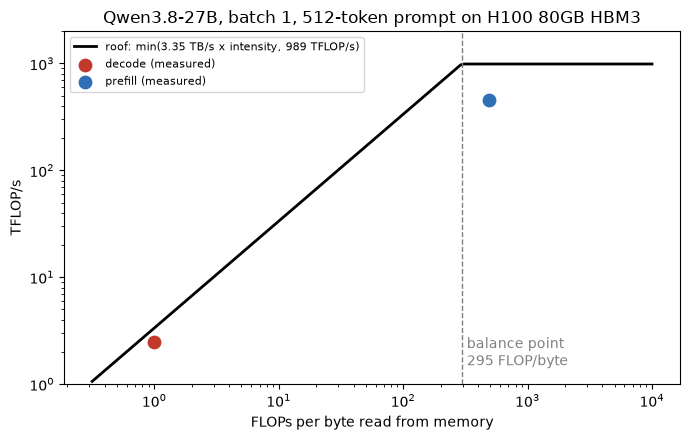

In [8]:
import numpy as np
ai = np.logspace(-0.5, 4, 200)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.loglog(ai, np.minimum(PEAK_TB * ai, PEAK_TF), "k-", lw=2, label=f"roof: min({PEAK_TB} TB/s x intensity, {PEAK_TF} TFLOP/s)")
ax.axvline(RIDGE, color="gray", ls="--", lw=1)
ax.text(RIDGE * 1.1, 1.5, f"balance point\n{RIDGE:.0f} FLOP/byte", color="gray")
ax.scatter([ai_dec], [FLOP_DECODE / dec_s / 1e12], s=80, color="#c0392b", zorder=3, label="decode (measured)")
ax.scatter([ai_pre], [FLOP_PREFILL / pre_s / 1e12], s=80, color="#2f6fb5", zorder=3, label="prefill (measured)")
ax.set(xlabel="FLOPs per byte read from memory", ylabel="TFLOP/s", ylim=(1, 2000),
       title=f"Qwen3.8-27B, batch 1, {INPUT_LEN}-token prompt on {match}")
ax.legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()